# Continuous XNOR — scaling and optimization controls

This notebook runs the three joint conditions over six scales and five initialization seeds. It is the main experiment: 90 default runs. It does not require a previous notebook's kernel state.

Keep the default 500-update budget for the research run. Set `QUICK_RUN=True` for a 25-update, one-seed preview at scales 1 and 5. Preview results have their own folder. `SHOW_LIVE` controls display only.

In [8]:
%matplotlib inline
from pathlib import Path
import sys
import json
import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, clear_output, Code

# Launch Jupyter here, or open these notebooks from the project root.
HERE = Path.cwd()
if not (HERE / 'notebook_experiment.py').exists():
    HERE = HERE / 'continuous_xnor'
assert (HERE / 'notebook_experiment.py').exists(), 'Launch Jupyter from the continuous_xnor folder.'
sys.path.insert(0, str(HERE))
from notebook_experiment import *
torch.set_num_threads(1)
RESULTS = HERE / 'results'
print('PyTorch:', torch.__version__)


PyTorch: 2.14.1+cpu


In [9]:
# Default research settings. Preview results go into a separate folder.
QUICK_RUN = False
SHOW_LIVE = True
SEEDS = [42, 43, 44, 45, 46]
STEPS = 500
LR = 0.03
if QUICK_RUN:
    SEEDS = [42]
    STEPS = 25
    RESULTS = RESULTS / 'preview'
splits = make_splits()
train_data = splits['train']
validation_data = splits['validation']
test_data = splits['test']
print('Updates:', STEPS, '| seeds:', SEEDS, '| output:', RESULTS)
ALPHAS = [0.1, 0.5, 1, 2, 5, 10]
if QUICK_RUN:
    ALPHAS = [1, 5]
conditions = ['ordinary', 'inverse_init', 'compensated_sgd']
save_splits(RESULTS, splits)
print('Joint runs:', len(SEEDS) * len(ALPHAS) * len(conditions))


Updates: 500 | seeds: [42, 43, 44, 45, 46] | output: c:\Users\ESHAAN\HAKUR\SimpBias\continuous_xnor\results
Joint runs: 90


## What changes in each condition

1. **Ordinary scaling:** multiply the complex inputs by alpha, leaving numerical initialization unchanged.
2. **Inverse initialization:** also divide the two first-layer complex weight columns by alpha. Initial preactivations, gates, logits, and losses match the reference.
3. **Compensated SGD:** additionally divide those columns' gradients by alpha squared, after `backward()` and before `optimizer.step()`. This matches effective SGD updates when the starting functions are matched.

The same underlying signs and magnitudes are reused in all runs. There is no normalization, momentum, weight decay, or clipping. Each seed also has an auxiliary unscaled reference run for comparing final logits; these references are not additional rows in the 90-run summary.

In [10]:
def show_training(history, title):
    # Redraw every 100 updates and at the end, rather than creating hundreds
    # of figures for every model. All checkpoints are still recorded every 25.
    step = history[-1]['step']
    if step % 100 != 0 and step != STEPS:
        return
    frame = pd.DataFrame(history)
    clear_output(wait=True)
    has_conflicts = 'complex_conflict_agreement' in frame
    fig, axes = plt.subplots(1, 3 if has_conflicts else 2, figsize=(13, 3.3))
    for split in ['train', 'validation']:
        axes[0].plot(frame.step, frame[f'{split}_loss'], label=split)
        axes[1].plot(frame.step, frame[f'{split}_accuracy'], label=split)
    axes[0].set(title='BCE loss', xlabel='SGD step')
    axes[1].set(title='Accuracy', xlabel='SGD step', ylim=(-0.05, 1.05))
    if has_conflicts:
        axes[2].plot(frame.step, frame.complex_conflict_agreement, label='complex rule')
        axes[2].set(title='Conflict agreement', xlabel='SGD step', ylim=(-0.05, 1.05))
    for ax in axes:
        ax.grid(alpha=0.2)
        ax.legend()
    fig.suptitle(f'{title} | step {step}/{STEPS}')
    fig.tight_layout()
    display(fig)
    plt.close(fig)
    print('Current validation accuracy:', round(history[-1]['validation_accuracy'], 4))


## Run the sweep and watch training

Live curves show training/validation loss and accuracy, plus preference on the fixed independent conflict set. Validation counterfactual metrics are recorded at every checkpoint. Final held-out metrics use the test split only after training. Conflict agreement is not ordinary classification accuracy.

KeyboardInterrupt: 

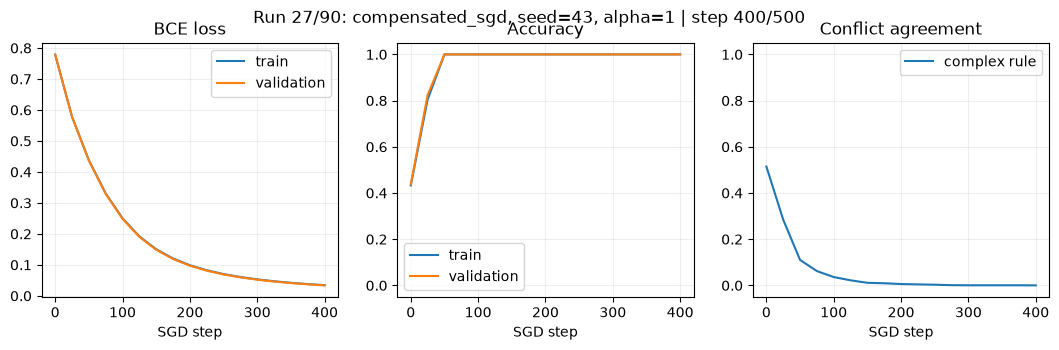

In [11]:
final_rows, history_rows = [], []
run_number = 0
total_runs = len(SEEDS) * len(ALPHAS) * len(conditions)
# Scaling copies the fixed samples: no signs or magnitudes are resampled.
scaled_splits = {alpha: {name: scale_data(data, alpha) for name, data in splits.items()}
                 for alpha in ALPHAS}
for seed in SEEDS:
    initial_reference = make_model(seed)
    final_reference = make_model(seed)
    train_model(final_reference, train_data, validation_data, steps=STEPS, lr=LR)
    with torch.no_grad():
        reference_logits = final_reference(test_data[0])
    for alpha in ALPHAS:
        data = scaled_splits[alpha]
        for condition in conditions:
            run_number += 1
            title = f'Run {run_number}/{total_runs}: {condition}, seed={seed}, alpha={alpha}'
            model = make_model(seed)
            checks = {'initial_preactivation_max_error': None,
                      'initial_logit_max_error': None,
                      'initial_gradient_scaling_max_error': None}
            if condition != 'ordinary':
                inverse_initialize(model, initial_reference, alpha)
                checks = initial_checks(initial_reference, model, train_data, data['train'], alpha)
            callback = (lambda history: show_training(history, title)) if SHOW_LIVE else None
            history = train_model(model, data['train'], data['validation'], steps=STEPS, lr=LR,
                                  alpha=alpha, compensate=(condition == 'compensated_sgd'),
                                  conflicts=data['conflicts'], on_log=callback)
            info = {'condition': condition, 'seed': seed, 'alpha': alpha}
            history_rows.extend({**info, **row} for row in history)
            final = {**info, **checks, **history[-1]}
            metrics = classification_metrics(model, data['test'])
            metrics.update(counterfactual_metrics(model, data['test'][0]))
            final.update({f'test_{k}': v for k, v in metrics.items()})
            with torch.no_grad():
                error = (model(data['test'][0]) - reference_logits).abs().max().item()
            final['final_test_logit_max_error_vs_alpha1'] = error
            final_rows.append(final)
            if not SHOW_LIVE:
                print(title, '| test accuracy:', round(final['test_accuracy'], 4))
            # Checkpoint completed runs so partial progress is not lost.
            save_rows(RESULTS / 'final_summary.csv', final_rows)
            save_rows(RESULTS / 'training_history.csv', history_rows)
save_json(RESULTS / 'metadata.json', {
    'dataset': 'continuous_xnor', 'magnitudes': 'independent Uniform(0.5, 1.5)',
    'normalization': 'none', 'seeds': SEEDS, 'alphas': ALPHAS, 'steps': STEPS, 'lr': LR,
    'data_seeds': {'train': 11, 'validation': 12, 'test': 13, 'conflicts': 14},
    'samples': {name: len(data[0]) for name, data in splits.items()},
    'model': 'Linear(3, 32) -> ReLU -> Linear(32, 1)',
    'optimizer': 'plain full-batch SGD; no momentum, weight decay, or clipping',
    'record_every': 25, 'conditions': conditions, 'auxiliary_reference_runs': len(SEEDS),
    'torch_version': torch.__version__,
})
print('Completed and saved', len(final_rows), 'joint runs to', RESULTS)


## Inspect numerical checks before interpreting preference

Inverse initialization errors should be small. Compensated final logits should match the unscaled reference up to numerical precision. Hard decisions can differ at an exceptionally near-zero logit even when numerical errors are small, so inspect logit errors as well as scores.

In [ ]:
final = pd.DataFrame(final_rows)
display(final[['condition', 'seed', 'alpha', 'train_accuracy', 'validation_accuracy',
               'test_accuracy', 'complex_conflict_agreement']])
check_columns = ['initial_preactivation_max_error', 'initial_logit_max_error',
                 'initial_gradient_scaling_max_error', 'final_test_logit_max_error_vs_alpha1']
display(final.groupby('condition')[check_columns].max())
print('Use Notebook 03 for graphs across scales, training checkpoints, and seed-level results.')


,condition,seed,alpha,train_accuracy,validation_accuracy,test_accuracy,complex_conflict_agreement
0,ordinary,42,0.1,1.0,1.0,1.0,0.000000
1,inverse_init,42,0.1,1.0,1.0,1.0,0.000000
2,compensated_sgd,42,0.1,1.0,1.0,1.0,0.005371
3,ordinary,42,0.5,1.0,1.0,1.0,0.000000
4,inverse_init,42,0.5,1.0,1.0,1.0,0.000000
...,...,...,...,...,...,...,...
85,inverse_init,46,5.0,1.0,1.0,1.0,0.725098
86,compensated_sgd,46,5.0,1.0,1.0,1.0,0.000000
87,ordinary,46,10.0,1.0,1.0,1.0,1.000000
88,inverse_init,46,10.0,1.0,1.0,1.0,1.000000


,initial_preactivation_max_error,initial_logit_max_error,initial_gradient_scaling_max_error,final_test_logit_max_error_vs_alpha1
condition,,,,
compensated_sgd,4.768372e-07,1.192093e-07,2.980232e-08,0.000003
inverse_init,4.768372e-07,1.192093e-07,2.980232e-08,7.303813
ordinary,NaN,NaN,NaN,9.484276


Use Notebook 03 for graphs across scales, training checkpoints, and seed-level results.
